<a href="https://colab.research.google.com/github/Guru1315/DAILY_PROJECTS_OF_ML-ALGORITHMS/blob/Linear_Regression/insurance_linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(url)
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [ ]:
print('Rows, columns:', df.shape)
print()
print('Missing values per column:')
print(df.isnull().sum())
print()
df.describe()

Rows, columns: (1338, 7)

Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64



,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


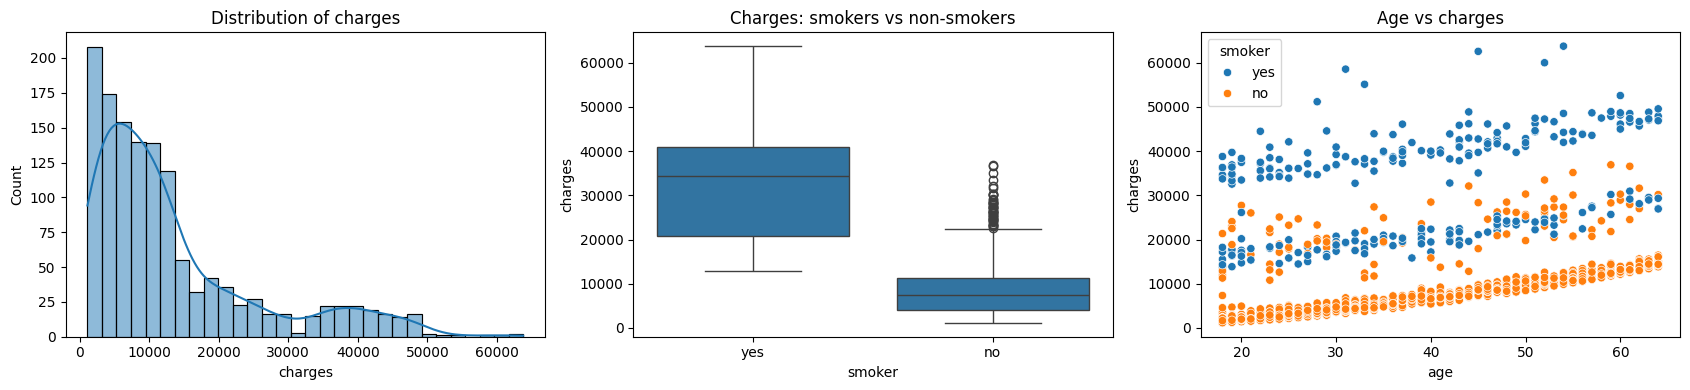

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

sns.histplot(df['charges'], kde=True, ax=axes[0])
axes[0].set_title('Distribution of charges')

sns.boxplot(x='smoker', y='charges', data=df, ax=axes[1])
axes[1].set_title('Charges: smokers vs non-smokers')

sns.scatterplot(x='age', y='charges', hue='smoker', data=df, ax=axes[2])
axes[2].set_title('Age vs charges')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True, dtype=int)
print(df_encoded.columns.tolist())

X = df_encoded.drop('charges', axis=1)   # features
y = df_encoded['charges']                # label

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('Training rows:', len(X_train), '| Test rows:', len(X_test))

['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']
Training rows: 1070 | Test rows: 268


In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)
print('Training finished.')

Training finished.


MAE  : 4181.19
RMSE : 5796.28
R2 (test) : 0.7836
R2 (train): 0.7417


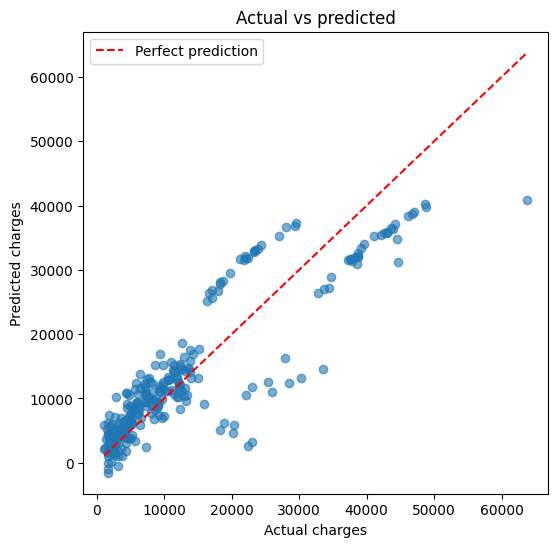

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pred = model.predict(X_test)

print('MAE  :', round(mean_absolute_error(y_test, pred), 2))
print('RMSE :', round(np.sqrt(mean_squared_error(y_test, pred)), 2))
print('R2 (test) :', round(r2_score(y_test, pred), 4))
print('R2 (train):', round(model.score(X_train, y_train), 4))

plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.6)
lims = [y.min(), y.max()]
plt.plot(lims, lims, 'r--', label='Perfect prediction')
plt.xlabel('Actual charges')
plt.ylabel('Predicted charges')
plt.title('Actual vs predicted')
plt.legend()
plt.show()

Intercept (bias): -11931.22

         feature  coefficient
      smoker_yes 23651.128856
        children   425.278784
             bmi   337.092552
             age   256.975706
        sex_male   -18.591692
region_northwest  -370.677326
region_southeast  -657.864297
region_southwest  -809.799354


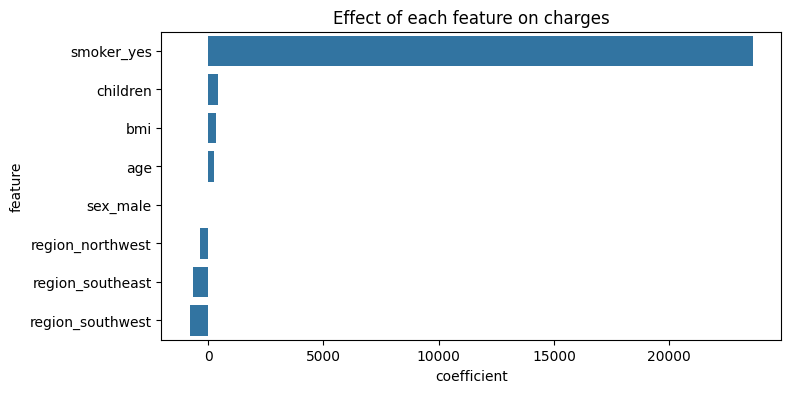

In [ ]:
coef = pd.DataFrame({'feature': X.columns, 'coefficient': model.coef_})
coef = coef.sort_values('coefficient', ascending=False)
print('Intercept (bias):', round(model.intercept_, 2))
print()
print(coef.to_string(index=False))

plt.figure(figsize=(8, 4))
sns.barplot(x='coefficient', y='feature', data=coef)
plt.title('Effect of each feature on charges')
plt.show()

In [ ]:
person = {
    'age': 30, 'bmi': 27.0, 'children': 1,
    'sex_male': 1, 'smoker_yes': 0,
    'region_northwest': 0, 'region_southeast': 1, 'region_southwest': 0,
}
new_X = pd.DataFrame([person])[X.columns]
print('Non-smoker:', round(model.predict(new_X)[0], 2))

person['smoker_yes'] = 1
new_X = pd.DataFrame([person])[X.columns]
print('Same person as smoker:', round(model.predict(new_X)[0], 2))

Non-smoker: 4628.37
Same person as smoker: 28279.5


In [ ]:
X2 = X.copy()
X2['age_sq'] = X2['age'] ** 2
X2['smoker_bmi'] = X2['smoker_yes'] * X2['bmi']

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42
)

model2 = LinearRegression().fit(X2_train, y2_train)
pred2 = model2.predict(X2_test)

print('Original model  R2:', round(r2_score(y_test, pred), 4), '| MAE:', round(mean_absolute_error(y_test, pred), 2))
print('Improved model  R2:', round(r2_score(y2_test, pred2), 4), '| MAE:', round(mean_absolute_error(y2_test, pred2), 2))

Original model  R2: 0.7836 | MAE: 4181.19
Improved model  R2: 0.8674 | MAE: 2755.47
